<a href="https://colab.research.google.com/github/Apoorva-code2005/Apoorva-code2005/blob/main/Copy_of_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!aws s3 sync --no-sign-request \
s3://physionet-open/ptb-xl/1.0.3/records100/ \
/content/ptb-xl/records100/

/bin/bash: line 1: aws: command not found


In [ ]:
!pip install awscli


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 94.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 23.1 MB/s  0:00:00
  Attempting uninstall: rsa
    Found existing installation: rsa 4.9.1
    Uninstalling rsa-4.9.1:
      Successfully uninstalled rsa-4.9.1
  Attempting uninstall: docutils
    Found existing installation: docutils 0.21.2
    Uninstalling docutils-0.21.2:
      Successfully uninstalled docutils-0.21.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [awscli]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [ ]:
!aws s3 sync \
--no-sign-request \
s3://physionet-open/ptb-xl/1.0.3/records100/ \
/content/ptb-xl/records100/

Streaming output truncated to the last 5000 lines.
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19334_lr.dat to ptb-xl/records100/19000/19334_lr.dat
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19338_lr.dat to ptb-xl/records100/19000/19338_lr.dat
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19337_lr.dat to ptb-xl/records100/19000/19337_lr.dat
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19340_lr.hea to ptb-xl/records100/19000/19340_lr.hea
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19339_lr.dat to ptb-xl/records100/19000/19339_lr.dat
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19341_lr.hea to ptb-xl/records100/19000/19341_lr.hea
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19340_lr.dat to ptb-xl/records100/19000/19340_lr.dat
download: s3://physionet-open/ptb-xl/1.0.3/records100/19000/19342_lr.dat to ptb-xl/records100/19000/19342_lr.dat
download: s3://physionet-open/ptb-xl/1.0.3/re

In [ ]:
import os

path = "/content/ptb-xl/records100"

dat_count = sum(
    f.endswith(".dat")
    for _, _, files in os.walk(path)
    for f in files
)

hea_count = sum(
    f.endswith(".hea")
    for _, _, files in os.walk(path)
    for f in files
)

print("DAT files:", dat_count)
print("HEA files:", hea_count)

if dat_count == 21837 and hea_count == 21837:
    print("SUCCESS: Dataset download verified!")
else:
    print("Some files may be missing. Check the download.")

DAT files: 21799
HEA files: 21799
Some files may be missing. Check the download.


In [ ]:
import os
import pandas as pd

BASE = "/content/ptb-xl"

df = pd.read_csv(
    os.path.join(BASE, "ptbxl_database.csv")
)

missing = []

for filename in df["filename_lr"]:

    record = os.path.join(BASE, filename)

    if not os.path.exists(record + ".dat"):
        missing.append(filename + ".dat")

    if not os.path.exists(record + ".hea"):
        missing.append(filename + ".hea")

print("Total metadata records:", len(df))
print("Missing files:", len(missing))

print("\nFirst 20 missing files:")
print(missing[:20])


FileNotFoundError: [Errno 2] No such file or directory: '/content/ptb-xl/ptbxl_database.csv'

In [ ]:
import os

BASE = "/content/ptb-xl"
os.makedirs(BASE, exist_ok=True)

print("Directory ready:", BASE)

Directory ready: /content/ptb-xl


In [ ]:
!wget -q https://physionet.org/files/ptb-xl/1.0.3/ptbxl_database.csv \
-O /content/ptb-xl/ptbxl_database.csv

!wget -q https://physionet.org/files/ptb-xl/1.0.3/scp_statements.csv \
-O /content/ptb-xl/scp_statements.csv

In [ ]:
import os

BASE = "/content/ptb-xl"

print("Database CSV:", os.path.exists(
    BASE + "/ptbxl_database.csv"
))

print("SCP CSV:", os.path.exists(
    BASE + "/scp_statements.csv"
))

Database CSV: True
SCP CSV: True


In [ ]:
import pandas as pd
import os

df = pd.read_csv(BASE + "/ptbxl_database.csv")

missing = []

for filename in df["filename_lr"]:
    record = os.path.join(BASE, filename)

    for ext in [".dat", ".hea"]:
        if not os.path.exists(record + ext):
            missing.append(filename + ext)

print("Total ECG records:", len(df))
print("Missing files:", len(missing))
print("Missing files list:", missing[:20])

Total ECG records: 21799
Missing files: 0
Missing files list: []


In [ ]:
!pip install wfdb

In [ ]:
import pandas as pd
import wfdb
import matplotlib.pyplot as plt
import os

BASE = "/content/ptb-xl"

df = pd.read_csv(
    BASE + "/ptbxl_database.csv"
)

record_path = os.path.join(
    BASE,
    df.iloc[0]["filename_lr"]
)

signal, fields = wfdb.rdsamp(record_path)

print("Signal shape:", signal.shape)
print("Sampling frequency:", fields["fs"])
print("Lead names:", fields["sig_name"])
print("Duration:", len(signal) / fields["fs"], "seconds")

Signal shape: (1000, 12)
Sampling frequency: 100
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Duration: 10.0 seconds


In [ ]:
import numpy as np

# Check the first ECG recording
print("NaN values:", np.isnan(signal).sum())
print("Infinite values:", np.isinf(signal).sum())

print("\nLead-wise signal statistics:")

for i, lead in enumerate(fields["sig_name"]):
    print(
        lead,
        "Min:", round(signal[:, i].min(), 4),
        "Max:", round(signal[:, i].max(), 4),
        "Mean:", round(signal[:, i].mean(), 4),
        "Std:", round(signal[:, i].std(), 4)
    )

NaN values: 0
Infinite values: 0

Lead-wise signal statistics:
I Min: -0.195 Max: 0.706 Mean: 0.0015 Std: 0.109
II Min: -0.14 Max: 0.435 Mean: 0.0007 Std: 0.0832
III Min: -0.312 Max: 0.13 Mean: -0.0008 Std: 0.0587
AVR Min: -0.559 Max: 0.138 Mean: -0.0011 Std: 0.0924
AVL Min: -0.155 Max: 0.5 Mean: 0.0012 Std: 0.077
AVF Min: -0.1 Max: 0.172 Mean: 0.0 Std: 0.0469
V1 Min: -0.704 Max: 0.142 Mean: -0.0017 Std: 0.1131
V2 Min: -1.377 Max: 0.41 Mean: 0.007 Std: 0.2142
V3 Min: -0.618 Max: 0.62 Mean: -0.0018 Std: 0.1178
V4 Min: -0.315 Max: 0.599 Mean: -0.0041 Std: 0.0954
V5 Min: -0.097 Max: 0.53 Mean: -0.0006 Std: 0.0892
V6 Min: -0.155 Max: 0.602 Mean: 0.0008 Std: 0.1019


In [ ]:
import pandas as pd

BASE = "/content/ptb-xl"

df = pd.read_csv(
    BASE + "/ptbxl_database.csv"
)

scp = pd.read_csv(
    BASE + "/scp_statements.csv",
    index_col=0
)

diagnostic_scp = scp[
    scp["diagnostic"] == 1
]

print("Diagnostic superclass distribution:")

print(
    diagnostic_scp["diagnostic_class"].value_counts()
)


Diagnostic superclass distribution:
diagnostic_class
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


In [ ]:
train_df = df[df["strat_fold"].between(1, 8)]
val_df = df[df["strat_fold"] == 9]
test_df = df[df["strat_fold"] == 10]

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nPatient counts:")

print("Train:", train_df["patient_id"].nunique())
print("Validation:", val_df["patient_id"].nunique())
print("Test:", test_df["patient_id"].nunique())

Training records: 17418
Validation records: 2183
Testing records: 2198

Patient counts:
Train: 15023
Validation: 1942
Test: 1904


In [ ]:
import ast
import pandas as pd

classes = ["NORM", "MI", "STTC", "CD", "HYP"]

diagnostic_scp = scp[scp["diagnostic"] == 1]

def get_diagnostic_classes(scp_codes):
    codes = ast.literal_eval(scp_codes)
    labels = set()

    for code in codes:
        if code in diagnostic_scp.index:
            cls = diagnostic_scp.loc[
                code, "diagnostic_class"
            ]
            if cls in classes:
                labels.add(cls)

    return sorted(labels)

df["labels"] = df["scp_codes"].apply(
    get_diagnostic_classes
)

for cls in classes:
    count = df["labels"].apply(
        lambda labels: cls in labels
    ).sum()

    print(f"{cls}: {count} ECG recordings")

NORM: 9514 ECG recordings
MI: 5469 ECG recordings
STTC: 5235 ECG recordings
CD: 4898 ECG recordings
HYP: 2649 ECG recordings


In [ ]:
train_df = df[df["strat_fold"].between(1, 8)]
val_df = df[df["strat_fold"] == 9]
test_df = df[df["strat_fold"] == 10]

train_ids = set(train_df["patient_id"])
val_ids = set(val_df["patient_id"])
test_ids = set(test_df["patient_id"])

print("Train/Validation overlap:", len(train_ids & val_ids))
print("Train/Test overlap:", len(train_ids & test_ids))
print("Validation/Test overlap:", len(val_ids & test_ids))

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)

print("Patient-independent split: PASSED")

Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0
Patient-independent split: PASSED


In [ ]:
import numpy as np
import pandas as pd
import wfdb
import os
from tqdm import tqdm

BASE = "/content/ptb-xl"

df = pd.read_csv(
    BASE + "/ptbxl_database.csv"
)

train_df = df[df["strat_fold"].between(1, 8)]

lead_sum = np.zeros(12, dtype=np.float64)
lead_sum_sq = np.zeros(12, dtype=np.float64)
total_samples = 0

for filename in tqdm(train_df["filename_lr"]):

    record_path = os.path.join(BASE, filename)

    signal, fields = wfdb.rdsamp(record_path)

    signal = signal.astype(np.float64)

    if signal.shape != (1000, 12):
        raise ValueError(
            f"Unexpected signal shape: {filename}"
        )

    if not np.isfinite(signal).all():
        raise ValueError(
            f"Invalid signal values: {filename}"
        )

    lead_sum += signal.sum(axis=0)
    lead_sum_sq += (signal ** 2).sum(axis=0)

    total_samples += signal.shape[0]

lead_mean = lead_sum / total_samples

lead_var = (
    lead_sum_sq / total_samples
) - (lead_mean ** 2)

lead_std = np.sqrt(np.maximum(lead_var, 0))

print("Training samples:", total_samples)
print("Lead means:", lead_mean)
print("Lead standard deviations:", lead_std)

100%|██████████| 17418/17418 [01:07<00:00, 256.96it/s]

Training samples: 17418000
Lead means: [-0.00172996 -0.00149454  0.00023504  0.00159292 -0.00093037 -0.00060511
  0.00016269 -0.00094584 -0.00155362 -0.00135555 -0.00080477 -0.00240096]
Lead standard deviations: [0.16083354 0.16422382 0.16707485 0.13945091 0.14194128 0.14472921
 0.23468495 0.33685744 0.3335852  0.29836872 0.27323134 0.2803845 ]


In [ ]:
import os
import numpy as np

params_path = "/content/ptb-xl/normalization_params.npz"

print("Parameters saved:", os.path.exists(params_path))

Parameters saved: False


In [ ]:
np.savez(
    params_path,
    mean=lead_mean,
    std=lead_std
)

In [ ]:
import os
import numpy as np

params_path = "/content/ptb-xl/normalization_params.npz"

print("Parameters saved:", os.path.exists(params_path))

Parameters saved: True


In [ ]:
import wfdb
import os
import numpy as np

sample_path = os.path.join(
    BASE,
    train_df.iloc[0]["filename_lr"]
)

raw_signal, fields = wfdb.rdsamp(sample_path)

params = np.load(params_path)

normalized = (
    raw_signal - params["mean"]
) / params["std"]

print("Original shape:", raw_signal.shape)
print("Normalized shape:", normalized.shape)

print("Normalized mean:")
print(normalized.mean(axis=0))

print("Normalized standard deviation:")
print(normalized.std(axis=0))

Original shape: (1000, 12)
Normalized shape: (1000, 12)
Normalized mean:
[ 0.02013238  0.01350313 -0.00606342 -0.01940413  0.01508629  0.00422933
 -0.00797532  0.02358518 -0.00066964 -0.00916132  0.0009068   0.01153046]
Normalized standard deviation:
[0.67785746 0.50676763 0.35151746 0.66247482 0.54224909 0.32379766
 0.48199708 0.63596526 0.35323466 0.31978774 0.32647934 0.3635701 ]


In [ ]:
import numpy as np

def simulate_missing_leads(signal, missing_ratio, seed=42):

    rng = np.random.default_rng(seed)

    corrupted = signal.copy()

    num_leads = signal.shape[0]

    num_missing = int(round(
        num_leads * missing_ratio
    ))

    missing_indices = rng.choice(
        num_leads,
        size=num_missing,
        replace=False
    )

    mask = np.ones(num_leads, dtype=np.float32)

    mask[missing_indices] = 0

    corrupted[missing_indices, :] = 0

    return corrupted, mask, missing_indices

In [ ]:
sample = normalized.T.astype(np.float32)

for ratio in [0.25, 0.50, 0.75]:

    corrupted, mask, missing = simulate_missing_leads(
        sample,
        ratio,
        seed=42
    )

    print("\nMissing ratio:", ratio)
    print("Missing leads:", missing)
    print("Availability mask:", mask)
    print("Output shape:", corrupted.shape)


Missing ratio: 0.25
Missing leads: [7 0 8]
Availability mask: [0. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1.]
Output shape: (12, 1000)

Missing ratio: 0.5
Missing leads: [ 5  6 10 11  4  0]
Availability mask: [0. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0.]
Output shape: (12, 1000)

Missing ratio: 0.75
Missing leads: [ 2  3  8  5  6 10  9  7  0]
Availability mask: [0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1.]
Output shape: (12, 1000)


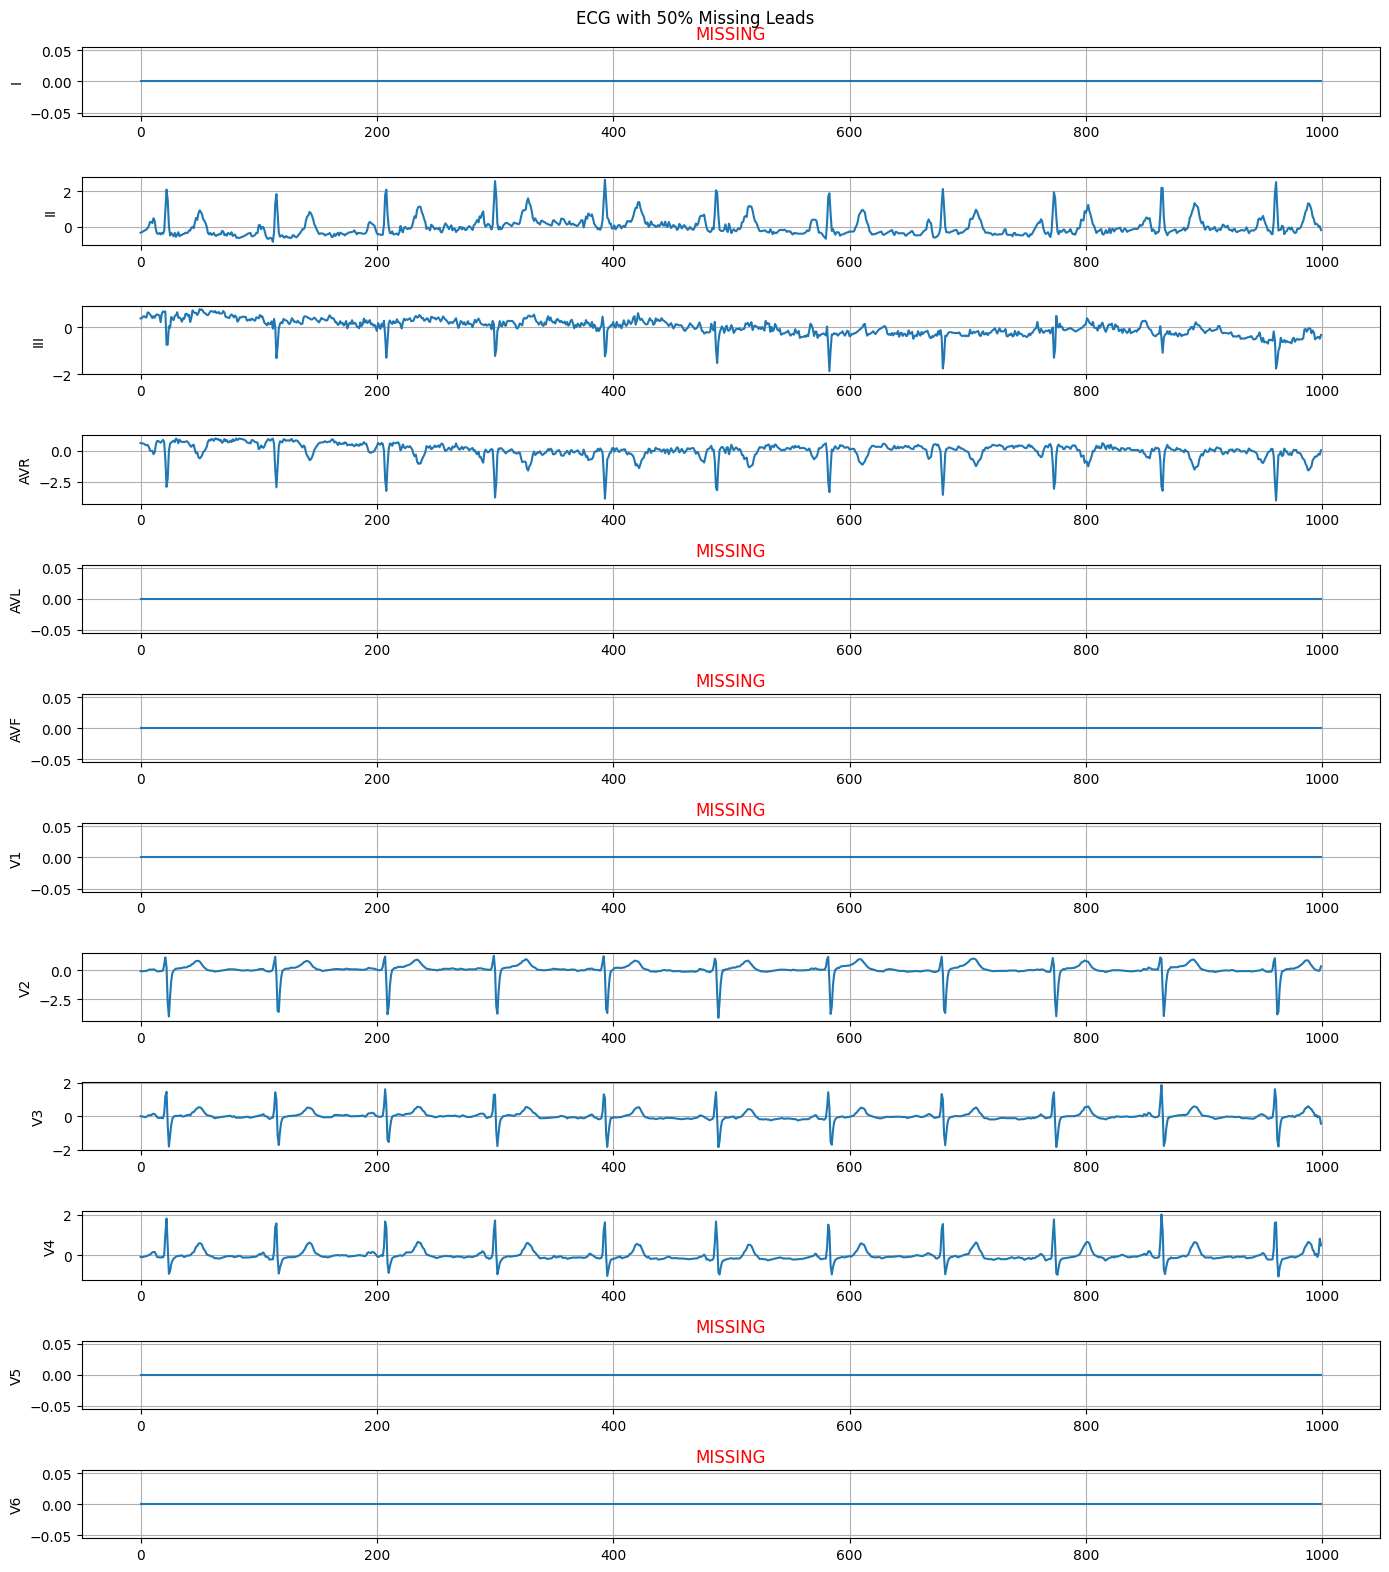

In [ ]:
import matplotlib.pyplot as plt

corrupted, mask, missing = simulate_missing_leads(
    sample, 0.50, seed=42
)

fig, axes = plt.subplots(12, 1, figsize=(14, 16))

for i in range(12):
    axes[i].plot(corrupted[i])
    axes[i].set_ylabel(fields["sig_name"][i])

    if mask[i] == 0:
        axes[i].set_title("MISSING", color="red")

    axes[i].grid(True)

plt.suptitle("ECG with 50% Missing Leads")
plt.tight_layout()
plt.show()